# 03 - Customer Segmentation (RFM)

**Phase 5.** Group customers by behaviour so the business can talk about them
in plain language: who are the champions, who is slipping away, who is already gone.

**Recency** - how long since they last bought
**Frequency** - how many orders they have placed
**Monetary** - how much they have spent

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
import config
from segmentation import build_rfm, segment_profile, SEGMENT_RULES

## 1. Build the RFM table

Measured as of the last date in the data (2011-12-09).

In [2]:
rfm = build_rfm()
print(f'{len(rfm):,} customers scored as of {rfm.asof_date.iat[0]}')
rfm.head()

4,334 customers scored as of 2011-12-09


,CustomerID,recency_days,frequency,monetary,first_purchase,last_purchase,country,avg_order_value,tenure_days,R,F,M,rfm_score,rfm_cell,segment,asof_date
0,12346,325,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom,77183.60,325,1,1,5,7,115,Lost Customers,2011-12-09
1,12347,1,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland,615.71,366,5,5,5,15,555,Champions,2011-12-09
2,12348,74,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00,Finland,449.31,357,2,4,4,10,244,At Risk,2011-12-09
3,12349,18,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00,Italy,1757.55,18,4,1,4,9,414,New Customers,2011-12-09
4,12350,309,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway,334.40,309,1,1,2,4,112,Lost Customers,2011-12-09


## 2. Scoring

Each dimension is cut into quintiles and scored 1-5, so the thresholds come from
this business's own customer distribution rather than from arbitrary numbers.
Recency is reversed - a *recent* buyer scores 5.

Ties are broken by ranking first. Without that, the many customers with exactly
one order would collapse the quintile edges onto each other.

In [3]:
for col, label in [('recency_days','R'), ('frequency','F'), ('monetary','M')]:
    edges = rfm.groupby(label)[col].agg(['min','max','count'])
    print(f'\n{label}  ({col})')
    for s, r in edges.iterrows():
        print(f'   score {s}: {r["min"]:>10,.0f} to {r["max"]:>10,.0f}   ({r["count"]:,} customers)')


R  (recency_days)
   score 1:        179 to        373   (867 customers)
   score 2:         71 to        178   (867 customers)
   score 3:         32 to         71   (866 customers)
   score 4:         13 to         32   (867 customers)
   score 5:          0 to         13   (867 customers)

F  (frequency)
   score 1:          1 to          1   (867 customers)
   score 2:          1 to          2   (867 customers)
   score 3:          2 to          3   (866 customers)
   score 4:          3 to          6   (867 customers)
   score 5:          6 to        206   (867 customers)

M  (monetary)
   score 1:          4 to        248   (867.0 customers)
   score 2:        248 to        488   (867.0 customers)
   score 3:        488 to        932   (866.0 customers)
   score 4:        933 to      2,048   (867.0 customers)
   score 5:      2,050 to    280,206   (867.0 customers)


## 3. Segment rules

Segments are assigned from the **Recency x Frequency** grid - the pair that
describes engagement. Monetary is held back for the separate Customer Value
Score in Phase 7, so that "how engaged is this customer" and "how much are they
worth" stay independent. That independence is what makes the Phase 8 priority
matrix meaningful.

Rules are applied in order, first match wins, and together they cover all 25
cells of the grid.

In [4]:
for i, (name, _) in enumerate(SEGMENT_RULES, 1):
    print(f'{i}. {name}')

grid = pd.crosstab(rfm.R, rfm.F)
display(grid)
seg_grid = rfm.pivot_table(index='R', columns='F', values='segment',
                           aggfunc=lambda s: s.mode().iat[0])
display(seg_grid)

1. Champions
2. Loyal Customers
3. Potential Loyalist
4. New Customers
5. At Risk
6. Lost Customers
7. Hibernating


F,1,2,3,4,5
R,,,,,
1,364,304,139,48,12
2,200,207,234,173,53
3,166,182,189,209,120
4,95,116,169,242,245
5,42,58,135,195,437


F,1,2,3,4,5
R,,,,,
1,Lost Customers,Lost Customers,At Risk,At Risk,At Risk
2,Hibernating,Hibernating,At Risk,At Risk,At Risk
3,Hibernating,Hibernating,Loyal Customers,Loyal Customers,Loyal Customers
4,New Customers,Potential Loyalist,Loyal Customers,Champions,Champions
5,New Customers,Potential Loyalist,Loyal Customers,Champions,Champions


## 4. The segments

In [5]:
prof = segment_profile(rfm)
prof

,segment,customers,avg_recency_days,avg_frequency,avg_monetary,total_revenue,pct_customers,pct_revenue
0,Champions,1119,12.0,10.0,5211.9,5832088.1,25.8,66.0
1,Loyal Customers,822,36.3,3.7,1652.5,1358358.1,19.0,15.4
2,Potential Loyalist,174,17.2,1.4,532.5,92647.9,4.0,1.0
3,New Customers,137,17.1,1.0,368.2,50441.7,3.2,0.6
4,At Risk,659,149.5,3.4,1240.0,817177.4,15.2,9.3
5,Hibernating,755,86.4,1.2,483.7,365224.1,17.4,4.1
6,Lost Customers,668,277.0,1.1,475.6,317686.6,15.4,3.6


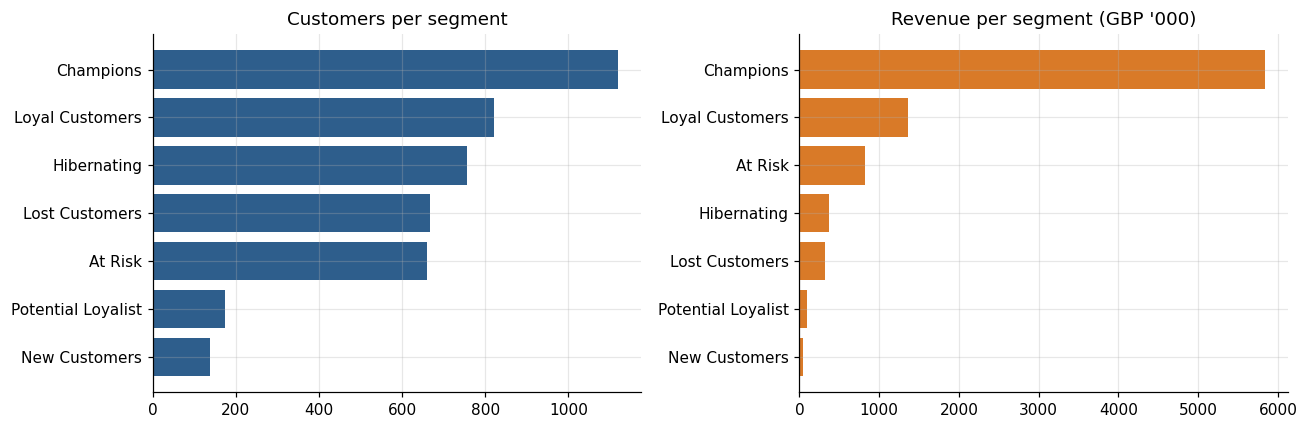

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
p = prof.sort_values('customers')
ax[0].barh(p.segment, p.customers, color='#2E5E8C')
ax[0].set_title('Customers per segment')
p2 = prof.sort_values('total_revenue')
ax[1].barh(p2.segment, p2.total_revenue/1000, color='#D97A28')
ax[1].set_title("Revenue per segment (GBP '000)")
plt.tight_layout(); plt.show()

### Reading the segments

* **Champions** - 26% of customers, **66% of revenue**. The business depends on them.
* **Loyal Customers** - a healthy 19% who buy regularly but spend less per head.
* **At Risk** - 659 customers who *used* to buy often and have now gone quiet for
  ~150 days on average, holding GBP 817k of historic revenue. This is the group
  retention spending exists for.
* **Hibernating / Lost** - 1,423 customers, mostly one-time buyers with low value.
  Cheap to email, not worth a phone call.
* **New / Potential Loyalist** - small groups, but this is where future Champions
  come from.

## 5. Where is the value concentrated?

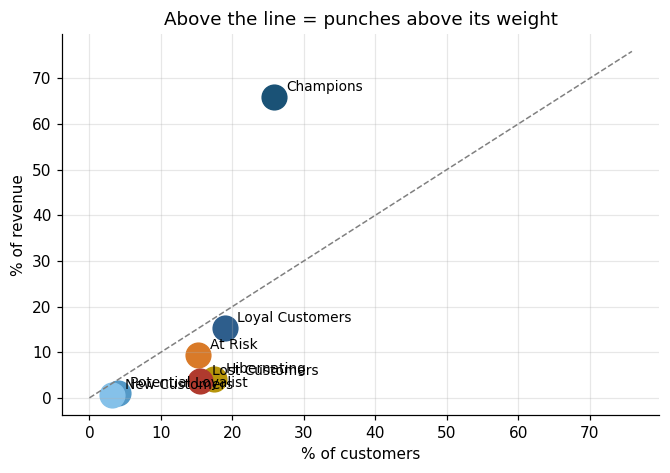

In [7]:
fig, ax = plt.subplots(figsize=(7,4.5))
colors = {'Champions':'#1A5276','Loyal Customers':'#2E5E8C','Potential Loyalist':'#5499C7',
          'New Customers':'#85C1E9','At Risk':'#D97A28','Hibernating':'#B7950B','Lost Customers':'#B03A2E'}
for _, r in prof.iterrows():
    ax.scatter(r.pct_customers, r.pct_revenue, s=260, color=colors.get(r.segment,'grey'))
    ax.annotate(r.segment, (r.pct_customers, r.pct_revenue),
                textcoords='offset points', xytext=(8,4), fontsize=9)
lim = max(prof.pct_customers.max(), prof.pct_revenue.max())*1.15
ax.plot([0,lim],[0,lim], ls='--', color='grey', lw=1)
ax.set_xlabel('% of customers'); ax.set_ylabel('% of revenue')
ax.set_title('Above the line = punches above its weight'); plt.show()

Only Champions sit meaningfully above the diagonal. Every other segment
contributes less revenue than its share of headcount - which is normal, and is
why a flat "email everyone" retention campaign wastes most of its budget.

## Limitation of segmentation alone

RFM describes what has **already happened**. It tells us a customer has gone
quiet, but by then they may already be gone. It also cannot distinguish a
customer who is 60 days silent because that is their normal rhythm from one who
is 60 days silent because they have left.

That is the gap the model in notebook 04 fills: predicting who is *about to*
become inactive, before it shows up in their recency score.